# Klasifikasi Jenis Serangan Jaringan (UNSW-NB15)

**Dataset:** `UNSW_NB15_training-set.csv` (82.332 baris) dan `UNSW_NB15_testing-set.csv` (175.341 baris), masing-masing 43 fitur jaringan.

**Tujuan (multikelas):** memprediksi `attack_cat`, yaitu **10 kategori**: *Normal* dan 9 jenis serangan (Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms).

**Catatan:** pada versi dataset ini file "training" justru **lebih kecil** daripada file "testing". Pembagian ini memang yang disediakan penyedia data, jadi dipakai apa adanya.

**Pertanyaan:**
1. Bagaimana komposisi tiap jenis serangan?
2. Serangan mana yang mudah dan mana yang sulit dideteksi?
3. Apa dampak ketimpangan kelas?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
sns.set_theme(style='whitegrid')
tr = pd.read_csv(cari('UNSW_NB15_training-set.csv')); te = pd.read_csv(cari('UNSW_NB15_testing-set.csv'))
print(tr.shape, te.shape)
tr.head(3)

(82332, 45) (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0


## 1. Pemahaman Data

In [2]:
print('Missing value train/test:', tr.isna().sum().sum(), '/', te.isna().sum().sum())
print('Kolom kategorikal:', ['proto','service','state'])
dist = pd.DataFrame({'train':tr.attack_cat.value_counts(), 'test':te.attack_cat.value_counts()})
dist['train_%'] = (dist.train/dist.train.sum()*100).round(2); dist['test_%'] = (dist.test/dist.test.sum()*100).round(2)
dist

Missing value train/test: 0 / 0
Kolom kategorikal: ['proto', 'service', 'state']


,train,test,train_%,test_%
attack_cat,,,,
Normal,37000,56000,44.94,31.94
Generic,18871,40000,22.92,22.81
Exploits,11132,33393,13.52,19.04
Fuzzers,6062,18184,7.36,10.37
DoS,4089,12264,4.97,6.99
Reconnaissance,3496,10491,4.25,5.98
Analysis,677,2000,0.82,1.14
Backdoor,583,1746,0.71,1.00
Shellcode,378,1133,0.46,0.65


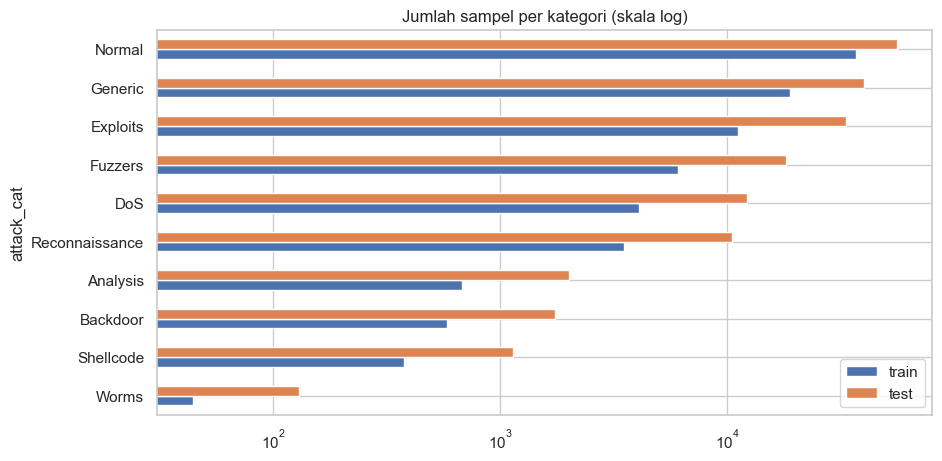

In [3]:
dist[['train','test']].sort_values('train').plot.barh(figsize=(10,5), logx=True, title='Jumlah sampel per kategori (skala log)'); plt.show()

**Temuan penting:**
- Data **sangat timpang**: *Normal*, *Generic*, dan *Exploits* mendominasi, sedangkan **Worms hanya 44 sampel** (train) dan Shellcode, Backdoor, Analysis juga sangat sedikit.
- Komposisi kelas di train dan test **tidak sama persis**, jadi model akan menghadapi distribusi yang sedikit berbeda.
- Karena timpang, *accuracy* **menyesatkan**. Metrik yang dipakai adalah **F1-macro** (rata-rata F1 semua kelas dengan bobot sama) dan recall per kelas.

## 2. Pra-pemrosesan

In [4]:
kat = ['proto','service','state']
fitur = [c for c in tr.columns if c not in ['id','attack_cat','label']]
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(tr[kat])
def siap(d):
    X = d[fitur].copy(); X[kat] = enc.transform(d[kat]); return X
Xtr, Xte = siap(tr), siap(te)
kelas = sorted(tr.attack_cat.unique())
ytr, yte = tr.attack_cat, te.attack_cat
print('Jumlah fitur:', Xtr.shape[1]); print('Kategori proto unik:', tr.proto.nunique())

Jumlah fitur: 42
Kategori proto unik: 131


Kolom `proto`, `service`, dan `state` diubah menjadi angka dengan *ordinal encoding* (cukup untuk model berbasis pohon). Kategori yang tidak pernah muncul di data latih diberi kode -1. Kolom `id` dan `label` (penanda serangan/normal) dibuang agar tidak terjadi **kebocoran informasi**.

## 3. Pemodelan

In [5]:
models = {
 'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=25, class_weight='balanced_subsample', n_jobs=-1, random_state=42),
 'Gradient Boosting': HistGradientBoostingClassifier(max_iter=120, class_weight='balanced', random_state=42),
}
hasil, preds = {}, {}
for n,m in models.items():
    m.fit(Xtr, ytr); preds[n] = m.predict(Xte)
    hasil[n] = dict(accuracy=accuracy_score(yte, preds[n]), F1_macro=f1_score(yte, preds[n], average='macro'), F1_weighted=f1_score(yte, preds[n], average='weighted'))
pd.DataFrame(hasil).T.round(4)

,accuracy,F1_macro,F1_weighted
Random Forest,0.7475,0.5054,0.7236
Gradient Boosting,0.7637,0.5495,0.7604


**Cara membaca:** selisih antara `accuracy`/`F1_weighted` dan `F1_macro` menunjukkan seberapa buruk model pada kelas langka. Kalau F1_macro jauh lebih rendah, artinya kelas kecil banyak terlewat.

In [6]:
best = max(hasil, key=lambda k: hasil[k]['F1_macro']); p = preds[best]
print('Model terbaik (F1-macro):', best)
print(classification_report(yte, p, digits=3, zero_division=0))

Model terbaik (F1-macro): Gradient Boosting
                precision    recall  f1-score   support

      Analysis      0.049     0.056     0.052      2000
      Backdoor      0.116     0.121     0.119      1746
           DoS      0.334     0.734     0.459     12264
      Exploits      0.867     0.491     0.627     33393
       Fuzzers      0.728     0.326     0.450     18184
       Generic      0.994     0.984     0.989     40000
        Normal      0.823     0.954     0.884     56000
Reconnaissance      0.815     0.805     0.810     10491
     Shellcode      0.441     0.840     0.578      1133
         Worms      0.431     0.677     0.527       130

      accuracy                          0.764    175341
     macro avg      0.560     0.599     0.549    175341
  weighted avg      0.807     0.764     0.760    175341



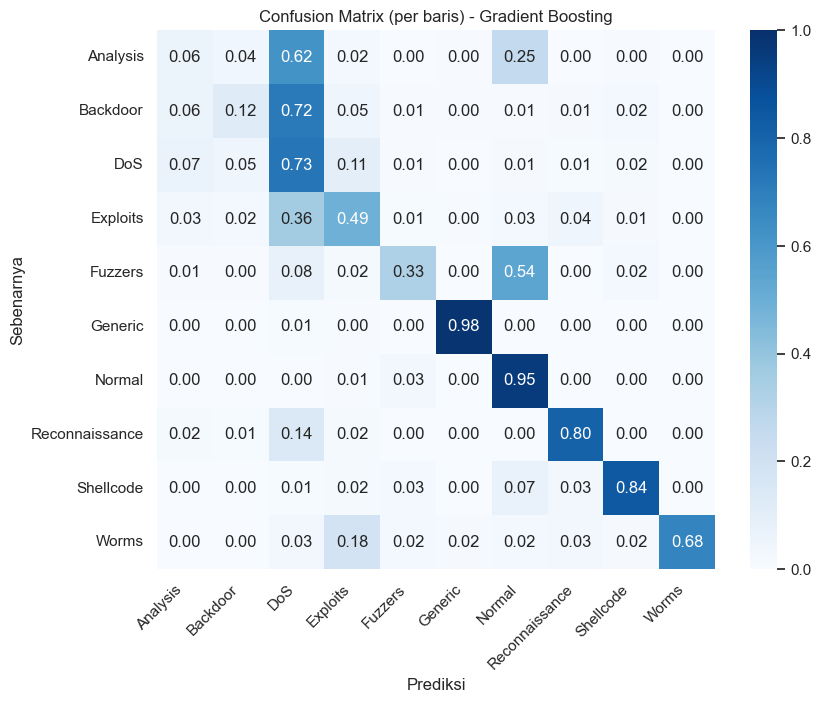

In [7]:
cm = confusion_matrix(yte, p, labels=kelas, normalize='true')
plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='.2f', xticklabels=kelas, yticklabels=kelas, cmap='Blues', vmax=1)
plt.xlabel('Prediksi'); plt.ylabel('Sebenarnya'); plt.title(f'Confusion Matrix (per baris) - {best}'); plt.xticks(rotation=45, ha='right'); plt.show()

Baca per **baris**: tiap angka menunjukkan proporsi serangan sebenarnya yang diprediksi sebagai kategori di kolom tersebut. Angka besar di luar diagonal menandakan kategori yang sering tertukar (misalnya *Exploits* dengan *DoS*, atau *Analysis* dengan *Backdoor*).

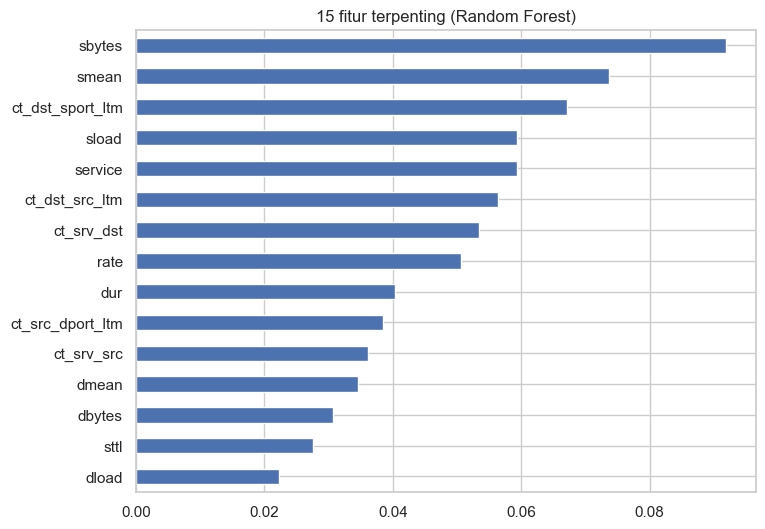

In [8]:
imp = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42).fit(Xtr, ytr)
pd.Series(imp.feature_importances_, index=fitur).sort_values().tail(15).plot.barh(figsize=(8,6), title='15 fitur terpenting (Random Forest)'); plt.show()

## 4. Kesimpulan
- Dataset **10 kelas dan sangat timpang**: *Normal*, *Generic*, dan *Exploits* dominan, sedangkan *Worms*, *Shellcode*, *Backdoor*, dan *Analysis* sangat langka.
- Hasil terbaik (Gradient Boosting): akurasi **± 76,4%** tetapi F1-macro hanya **± 0,55**, selisih ini menunjukkan banyak kelas yang buruk. *Generic* (F1 ± 0,99), *Normal* (± 0,88), dan *Reconnaissance* (± 0,81) dikenali dengan baik.
- Paling sulit: **Analysis (F1 ± 0,05)** dan **Backdoor (± 0,12)**, bahkan lebih buruk daripada *Worms* (± 0,53) yang jumlahnya paling sedikit. Artinya masalahnya bukan hanya jumlah sampel, tetapi pola *Analysis* dan *Backdoor* memang mirip lalu lintas lain.
- *Exploits* dan *Fuzzers* sering terlewat (recall ± 0,49 dan ± 0,33) dan banyak diprediksi sebagai DoS, sehingga precision DoS rendah (± 0,33).
- Pembobotan kelas (`class_weight`) membantu, tetapi untuk kelas dengan puluhan sampel diperlukan data tambahan atau teknik *resampling* (misalnya SMOTE).
- Fitur terpenting (umumnya terkait TTL, ukuran paket rata-rata, dan statistik koneksi `ct_*`) bisa dijadikan acuan fitur yang perlu dipantau pada sistem deteksi intrusi.
- **Catatan:** hanya file training/testing yang dipakai. Empat file mentah `UNSW-NB15_1..4.csv` (± 600 MB) tidak dipakai karena terlalu besar dan sudah terwakili oleh kedua file ringkasan itu.